<a href="https://colab.research.google.com/github/YudiH11/MSSP6070/blob/master/Assignments/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv('https://github.com/YudiH11/MSSP6070/raw/refs/heads/master/Assignments/InternetSales.csv', encoding="cp1252", low_memory=False)
df.head()

,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [ ]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])
df['Year'] = df['OrderDate'].dt.year
df[['OrderDate', 'Year']].head()

,OrderDate,Year
0,2011-01-19,2011
1,2013-01-18,2013
2,2013-01-18,2013
3,2013-05-03,2013
4,2013-05-03,2013


In [ ]:
#Internet Sales
#Firstly, calculate for the whole amount, which is yearly sales.
yearly_sales = (df.groupby('Year')['SalesAmount'].sum().reset_index())
yearly_sales

,Year,SalesAmount
0,2010,4.342104e+04
1,2011,7.075526e+06
2,2012,5.842485e+06
3,2013,1.635155e+07
4,2014,4.569472e+04


In [ ]:
#per country per year for sales amount.
country_year_sales = (df.groupby(['Year', 'EnglishCountryRegionName'])['SalesAmount'].sum().reset_index())
country_pivot = country_year_sales.pivot(index='Year', columns='EnglishCountryRegionName', values='SalesAmount')
country_pivot.round(2)

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
Year,,,,,,
2010,20909.78,3578.27,3399.99,NaN,699.10,14833.90
2011,2563732.25,571571.80,410845.33,520500.16,550591.22,2458285.17
2012,2128407.46,307604.52,648065.54,608657.98,712700.96,1437048.73
2013,4339443.38,1085632.65,1578511.80,1761876.36,2124007.29,5462078.86
2014,8507.72,9457.62,3195.06,3277.83,3713.64,17542.85


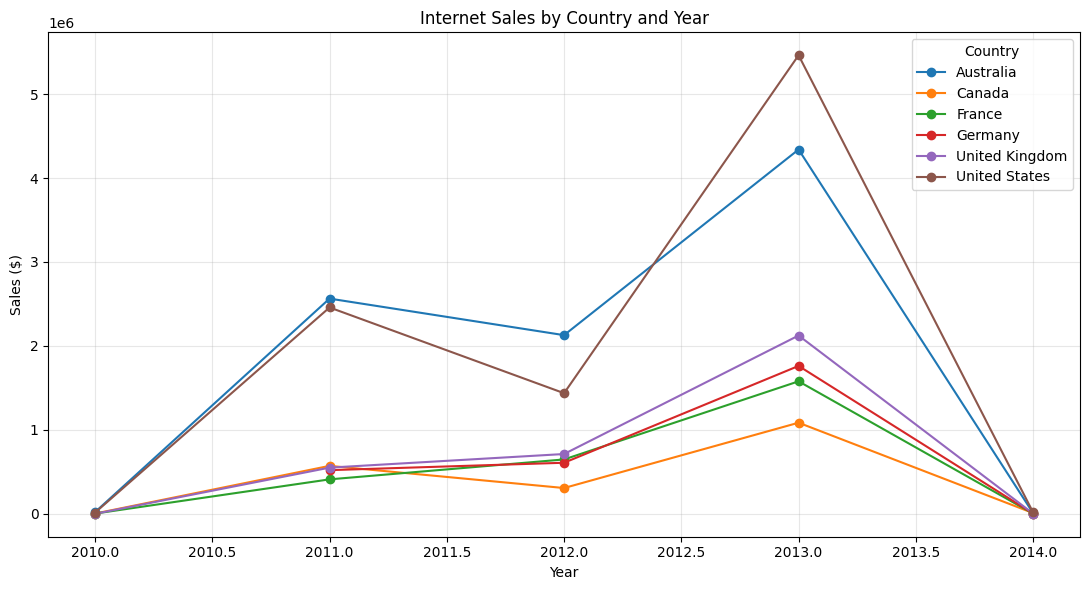

In [ ]:
country_pivot.plot(kind="line", marker="o", figsize=(11, 6))
plt.title("Internet Sales by Country and Year")
plt.xlabel("Year")
plt.ylabel("Sales ($)")
plt.legend(title="Country")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
#gender
#First, create customers datasite
customers = df.drop_duplicates(subset="CustomerKey")
customers.shape

(18484, 61)

In [ ]:
income_stats = (customers.groupby(["EnglishCountryRegionName", "Gender"])["YearlyIncome"]
    .agg(["count", "min", "max", "mean", "std"])
    .round(2))
income_stats

count    min     max      mean       std
EnglishCountryRegionName Gender                                          
Australia                F        1777  10000  160000  65284.19  31164.36
                         M        1814  10000  170000  63412.35  32450.71
Canada                   F         767  10000  170000  56505.87  19181.55
                         M         804  10000  170000  57798.51  21214.77
France                   F         893  10000  110000  35341.55  26915.85
                         M         917  10000  110000  36172.30  27633.45
Germany                  F         874  10000  130000  43810.07  35715.76
                         M         906  10000  130000  42108.17  35277.49
United Kingdom           F         934  10000  170000  52184.15  48288.44
                         M         979  10000  170000  52155.26  48593.22
United States            F        3888  10000  170000  63276.75  25166.56
                         M        3931  10000  170000  63953.19  26228.43

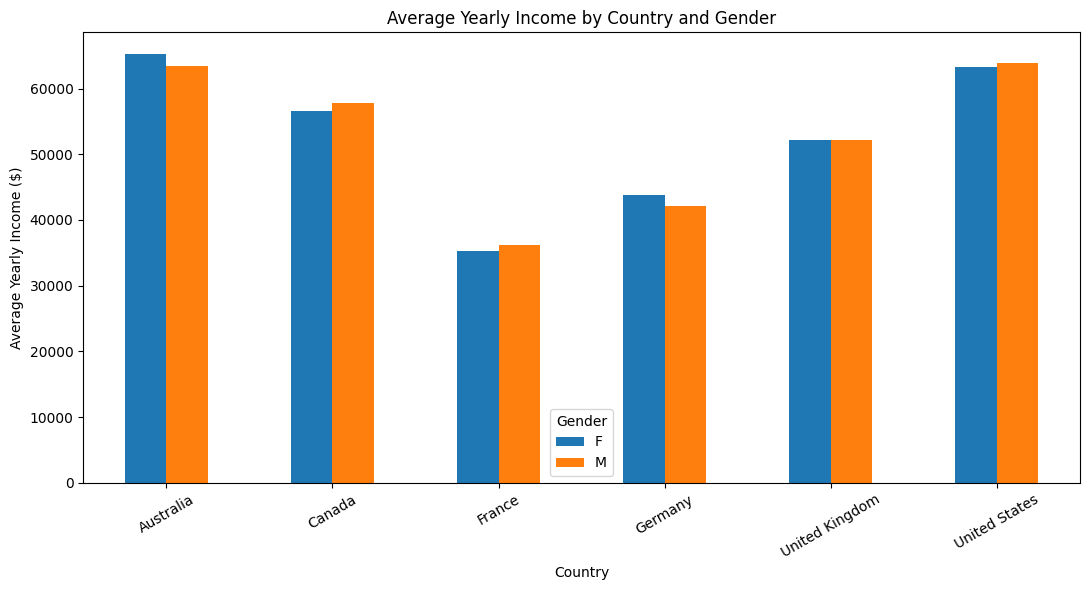

In [ ]:
income_plot = (customers.groupby(["EnglishCountryRegionName", "Gender"])["YearlyIncome"]
    .mean()
    .unstack())
income_plot.plot(kind="bar",figsize=(11, 6))
plt.title("Average Yearly Income by Country and Gender")
plt.xlabel("Country")
plt.ylabel("Average Yearly Income ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
#3. average price
def classify_product(name):
    if name.startswith(("Mountain-", "Road-", "Touring-")): return "Bikes"
    elif any(word in name for word in
             ["Jersey", "Shorts", "Gloves", "Socks", "Vest"]):
        return "Clothing"
    else:
        return "Accessories"

df["ProductCategory"] = df["EnglishProductName"].apply(classify_product)

df[["EnglishProductName", "ProductCategory"]].head()

,EnglishProductName,ProductCategory
0,"Mountain-100 Silver, 38",Bikes
1,"Mountain-200 Silver, 38",Bikes
2,Fender Set - Mountain,Accessories
3,"Touring-1000 Blue, 46",Bikes
4,Touring Tire,Accessories


In [ ]:
#Total amount of saling goods
category_sales = (df.groupby("ProductCategory")["SalesAmount"]
    .sum()
    .sort_values(ascending=False))
category_sales

,SalesAmount
ProductCategory,
Bikes,2.831814e+07
Accessories,7.204481e+05
Clothing,3.200845e+05


In [ ]:
# average unit price
top_category = category_sales.idxmax()

average_price = df.loc[df["ProductCategory"] == top_category,"UnitPrice"].mean()
top_category
round(average_price, 2)

np.float64(1862.42)

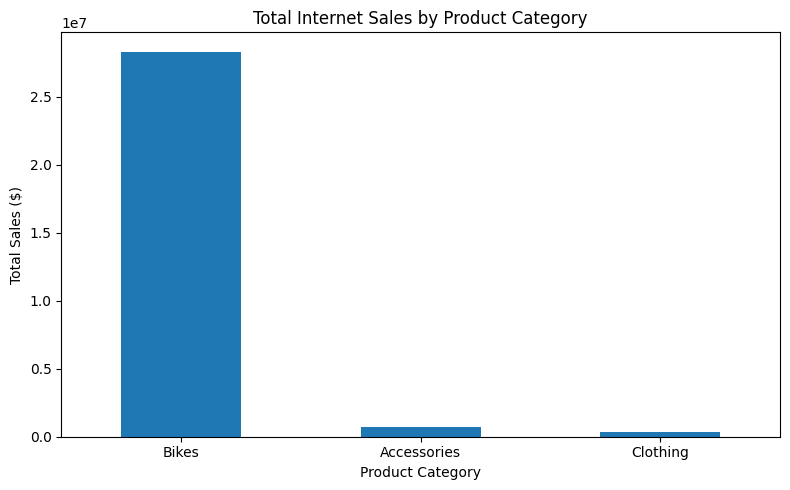

In [ ]:
category_sales.plot(kind="bar", figsize=(8, 5))

plt.title("Total Internet Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
#4.owning a home make a difference in sales?
home_stats = (df.groupby("HouseOwnerFlag")
    .agg(total_sales=("SalesAmount", "sum"),
        orders=("SalesOrderNumber", "nunique"),
        customers=("CustomerKey", "nunique")))

home_stats["sales_per_customer"] = (home_stats["total_sales"] / home_stats["customers"])

home_stats["avg_order_value"] = (home_stats["total_sales"] / home_stats["orders"])

home_stats.round(2)

,total_sales,orders,customers,sales_per_customer,avg_order_value
HouseOwnerFlag,,,,,
0,8973327.42,8601,5982,1500.05,1043.29
1,20385349.80,19058,12502,1630.57,1069.65
